
# Case Study 4: Sentiment Analysis on Product Reviews

Sentiment Analysis is an NLP technique used to classify customer reviews as Positive, Neutral, or Negative.

In this case study, we use Amazon product reviews to compare two models: LSTM and pre-trained BERT.

**Objective:** To analyze customer opinions and compare model performance using accuracy and other evaluation metrics.


In [ ]:
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Libraries imported successfully!")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas: 2.2.3
NumPy: 2.1.3
Libraries imported successfully!


In [ ]:
file_path = "/content/Reviews.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Reviews.csv not found. Please check the uploaded file path."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

display(df.head())

In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nRating distribution, if Score/Rating column exists:")
for col in df.columns:
    if col.strip().lower() in ["score", "rating", "star_rating", "overall"]:
        print(df[col].value_counts(dropna=False).sort_index())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84867 entries, 0 to 84866
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Id                      84867 non-null  int64 
 1   ProductId               84867 non-null  object
 2   UserId                  84867 non-null  object
 3   ProfileName             84861 non-null  object
 4   HelpfulnessNumerator    84867 non-null  int64 
 5   HelpfulnessDenominator  84867 non-null  int64 
 6   Score                   84867 non-null  int64 
 7   Time                    84867 non-null  int64 
 8   Summary                 84865 non-null  object
 9   Text                    84867 non-null  object
dtypes: int64(5), object(5)
memory usage: 6.5+ MB

Missing values:
Id                        0
ProductId                 0
UserId                    0
ProfileName               6
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score      

In [ ]:
def normalize_column(name):
    return str(name).strip().lower().replace(" ", "").replace("_", "")

column_map = {
    normalize_column(col): col for col in df.columns
}

text_candidates = [
    "text", "reviewtext", "review", "content",
    "verifiedreviews", "reviewbody"
]

rating_candidates = [
    "score", "rating", "starrating", "overall", "stars"
]

text_col = next(
    (column_map[c] for c in text_candidates if c in column_map),
    None
)

rating_col = next(
    (column_map[c] for c in rating_candidates if c in column_map),
    None
)

print("Detected review column:", text_col)
print("Detected rating column:", rating_col)

if text_col is None or rating_col is None:
    raise ValueError(
        "Review/rating column not detected. "
        "Check Cell 2 column names and update the candidates."
    )

Detected review column: Text
Detected rating column: Score


In [ ]:
data = df[[text_col, rating_col]].copy()
data.columns = ["review", "rating"]

data["review"] = data["review"].fillna("").astype(str).str.strip()
data["rating"] = pd.to_numeric(data["rating"], errors="coerce")

data = data[
    (data["review"].str.len() > 0) &
    (data["rating"].between(1, 5))
].copy()

data["label"] = np.select(
    [
        data["rating"] <= 2,
        data["rating"] == 3,
        data["rating"] >= 4
    ],
    [0, 1, 2],
    default=-1
)

data["label"] = data["label"].astype(int)
data = data.drop_duplicates(subset=["review"]).reset_index(drop=True)

# Use a manageable sample for the first experiment
if len(data) > 5000:
    data = data.sample(n=5000, random_state=SEED).reset_index(drop=True)

label_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

print("Cleaned dataset shape:", data.shape)
print("\nSentiment counts:")
print(data["label"].map(label_names).value_counts())

display(data.head())

Cleaned dataset shape: (5000, 3)

Sentiment counts:
label
Positive    3811
Negative     775
Neutral      414
Name: count, dtype: int64


,review,rating,label
0,This was easy to dissolve in either cold or ho...,4,2
1,I like to combine Tilda's Basmati & Wild Rice ...,5,2
2,This ginger drink is excellent. I would recomm...,5,2
3,Every pup I have ever owned LOVED these treats...,5,2
4,Tastes Great! My wife and I drink this tea on...,5,2


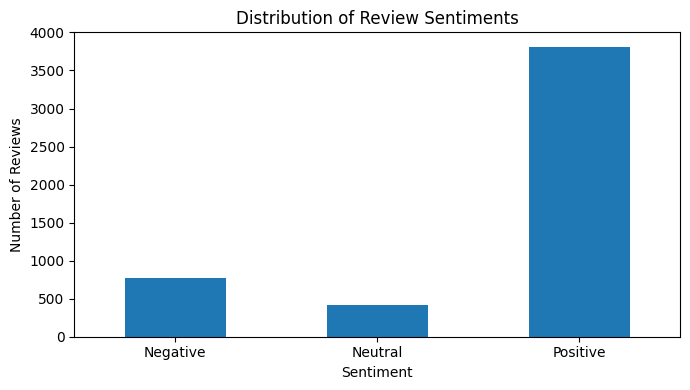

In [ ]:
counts = data["label"].map(label_names).value_counts()

counts = counts.reindex(
    ["Negative", "Neutral", "Positive"],
    fill_value=0
)

counts.plot(kind="bar", figsize=(7, 4))
plt.title("Distribution of Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data["review"],
    data["label"],
    test_size=0.2,
    random_state=SEED,
    stratify=data["label"]
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Train-test split completed!")

Training samples: 4000
Testing samples: 1000
Train-test split completed!


In [ ]:
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available; training may be slower.")

PyTorch version: 2.11.0+cpu
Device: cpu
GPU not available; training may be slower.


In [ ]:
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader

MAX_VOCAB = 10000
MAX_LEN = 100

def tokenize(text):
    return str(text).lower().split()

word_counts = Counter()

for review in X_train:
    word_counts.update(tokenize(review))

word_to_id = {"<PAD>": 0, "<UNK>": 1}

for word, _ in word_counts.most_common(MAX_VOCAB - 2):
    word_to_id[word] = len(word_to_id)

def encode_review(review):
    ids = [
        word_to_id.get(word, 1)
        for word in tokenize(review)
    ]
    ids = ids[:MAX_LEN]
    ids += [0] * (MAX_LEN - len(ids))
    return ids

X_train_seq = torch.tensor(
    [encode_review(x) for x in X_train],
    dtype=torch.long
)

X_test_seq = torch.tensor(
    [encode_review(x) for x in X_test],
    dtype=torch.long
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.long
)

print("Vocabulary size:", len(word_to_id))
print("Training tensor:", X_train_seq.shape)
print("Testing tensor:", X_test_seq.shape)

Vocabulary size: 10000
Training tensor: torch.Size([4000, 100])
Testing tensor: torch.Size([1000, 100])


In [ ]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=64):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, 3)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        output = self.dropout(hidden[-1])
        return self.fc(output)


lstm_model = LSTMClassifier(
    vocab_size=len(word_to_id)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print(lstm_model)

LSTMClassifier(
  (embedding): Embedding(10000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)


In [ ]:
train_dataset = TensorDataset(
    X_train_seq,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

EPOCHS = 3

for epoch in range(EPOCHS):
    lstm_model.train()
    total_loss = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        outputs = lstm_model(batch_x)
        loss = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Loss: {total_loss / len(train_loader):.4f}"
    )

print("LSTM training completed!")

Epoch 1/3 | Loss: 0.7713
Epoch 2/3 | Loss: 0.6967
Epoch 3/3 | Loss: 0.6861
LSTM training completed!


In [ ]:
lstm_model.eval()
lstm_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_seq), 64):
        batch = X_test_seq[start:start + 64].to(device)
        logits = lstm_model(batch)

        lstm_predictions.extend(
            logits.argmax(dim=1).cpu().tolist()
        )

lstm_accuracy = accuracy_score(y_test, lstm_predictions)

lstm_precision, lstm_recall, lstm_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        lstm_predictions,
        average="weighted",
        zero_division=0
    )
)

print("LSTM Accuracy:", round(lstm_accuracy, 4))
print("LSTM Precision:", round(lstm_precision, 4))
print("LSTM Recall:", round(lstm_recall, 4))
print("LSTM F1-score:", round(lstm_f1, 4))

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    lstm_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

LSTM Accuracy: 0.763
LSTM Precision: 0.7362
LSTM Recall: 0.763
LSTM F1-score: 0.6614

Detailed classification report:
              precision    recall  f1-score   support

    Negative       1.00      0.01      0.01       155
     Neutral       0.00      0.00      0.00        83
    Positive       0.76      1.00      0.87       762

    accuracy                           0.76      1000
   macro avg       0.59      0.34      0.29      1000
weighted avg       0.74      0.76      0.66      1000



In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
).to(device)

print("BERT model loaded successfully!")
print("Device:", device)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!
Device: cpu


In [ ]:
from torch.utils.data import Dataset, DataLoader

MAX_BERT_LEN = 128
MAX_BERT_TRAIN = min(3000, len(X_train))

# Sample training data while preserving class proportions
X_bert_train, _, y_bert_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=MAX_BERT_TRAIN,
    random_state=SEED,
    stratify=y_train
)

train_encodings = tokenizer(
    X_bert_train.astype(str).tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_BERT_LEN,
    return_tensors="pt"
)

test_encodings = tokenizer(
    X_test.astype(str).tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_BERT_LEN,
    return_tensors="pt"
)

y_bert_train_tensor = torch.tensor(
    y_bert_train.to_numpy(),
    dtype=torch.long
)

y_bert_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.long
)

print("BERT training samples:", len(X_bert_train))
print("BERT testing samples:", len(X_test))
print("Tokenization completed!")

In [ ]:
class ReviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: value[idx]
            for key, value in self.encodings.items()
        }

        item["labels"] = self.labels[idx]
        return item


bert_train_dataset = ReviewDataset(
    train_encodings,
    y_bert_train_tensor
)

bert_train_loader = DataLoader(
    bert_train_dataset,
    batch_size=8,
    shuffle=True
)

bert_optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=2e-5
)

BERT_EPOCHS = 1

bert_model.train()

for epoch in range(BERT_EPOCHS):
    total_loss = 0

    for batch in bert_train_loader:
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        bert_optimizer.zero_grad()

        outputs = bert_model(**batch)
        loss = outputs.loss

        loss.backward()
        bert_optimizer.step()

        total_loss += loss.item()

    print(
        f"BERT Epoch {epoch + 1}/{BERT_EPOCHS} | "
        f"Loss: {total_loss / len(bert_train_loader):.4f}"
    )

print("BERT fine-tuning completed!")

In [ ]:
bert_test_dataset = ReviewDataset(
    test_encodings,
    y_bert_test_tensor
)

bert_test_loader = DataLoader(
    bert_test_dataset,
    batch_size=8,
    shuffle=False
)

bert_model.eval()
bert_predictions = []

with torch.no_grad():
    for batch in bert_test_loader:
        batch.pop("labels")

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = bert_model(**batch)

        bert_predictions.extend(
            outputs.logits.argmax(dim=1).cpu().tolist()
        )

bert_accuracy = accuracy_score(y_test, bert_predictions)

bert_precision, bert_recall, bert_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        bert_predictions,
        average="weighted",
        zero_division=0
    )
)

print("BERT Accuracy:", round(bert_accuracy, 4))
print("BERT Precision:", round(bert_precision, 4))
print("BERT Recall:", round(bert_recall, 4))
print("BERT F1-score:", round(bert_f1, 4))

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    bert_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

In [ ]:
results = pd.DataFrame({
    "Model": ["LSTM", "BERT"],
    "Accuracy": [lstm_accuracy, bert_accuracy],
    "Precision": [lstm_precision, bert_precision],
    "Recall": [lstm_recall, bert_recall],
    "F1-score": [lstm_f1, bert_f1]
})

print("Model Comparison:")
display(results.round(4))

results.to_csv(
    "sentiment_model_comparison.csv",
    index=False
)

print("Comparison saved successfully!")

In [ ]:
results.set_index("Model")[["Accuracy", "F1-score"]].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("LSTM vs BERT Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

In [ ]:
sentiment_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

def predict_sentiment(review):
    # LSTM prediction
    lstm_model.eval()

    sequence = torch.tensor(
        [encode_review(review)],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():
        lstm_pred = lstm_model(sequence).argmax(dim=1).item()

    # BERT prediction
    bert_model.eval()

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=MAX_BERT_LEN
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        bert_pred = bert_model(**inputs).logits.argmax(dim=1).item()

    print("Review:", review)
    print("LSTM prediction:", sentiment_names[lstm_pred])
    print("BERT prediction:", sentiment_names[bert_pred])
    print("-" * 45)


predict_sentiment("This product is excellent and works perfectly.")
predict_sentiment("The product is okay, nothing special.")
predict_sentiment("Very poor quality. I am disappointed.")

In [ ]:
print("""
CASE STUDY 4: SENTIMENT ANALYSIS ON PRODUCT REVIEWS

Objective:
Classify Amazon product reviews as Negative, Neutral, or Positive.

Methods:
1. Cleaned review text and converted star ratings into sentiment labels.
2. Trained an LSTM baseline model.
3. Fine-tuned a pre-trained Transformer model using Hugging Face.
4. Evaluated both models using Accuracy, Precision, Recall, and F1-score.
5. Compared their performance using a table and graph.

Transfer Learning:
BERT starts with language representations learned during pre-training.
Fine-tuning adapts the model to the sentiment classification task.

Deployment Challenges:
- Prediction latency
- Memory and computing cost
- Customer data privacy
- Class imbalance
- Sarcasm and changing language

Conclusion:
Choose the model based on measured test performance and deployment needs.
BERT is not guaranteed to outperform LSTM in every experiment.
""")

In [ ]:
# Save LSTM model and its vocabulary
torch.save({
    "model_state_dict": lstm_model.state_dict(),
    "word_to_id": word_to_id,
    "max_len": MAX_LEN
}, "lstm_sentiment_model.pt")

# Save fine-tuned BERT and tokenizer
bert_model.save_pretrained("fine_tuned_bert_sentiment")
tokenizer.save_pretrained("fine_tuned_bert_sentiment")

print("Models saved successfully!")